# Data Cleaning and Exploratory Data Analysis (EDA)

## Project: CivicFix

### Objective
Clean the extracted NYC 311 dataset, create the target variable based on complaint resolution time, and perform exploratory data analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load extracted dataset
df = pd.read_csv("../data/processed/nyc_311_2020_2025.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (20000, 9)


,unique_key,created_date,closed_date,agency,complaint_type,descriptor,incident_zip,borough,location_type
0,45330366,2020-01-07 11:07:08,2020-02-10 00:00:00,DOB,Building/Use,Illegal Conversion Of Residential Building/Space,11378.0,QUEENS,NaN
1,45484120,2020-01-27 17:20:00,2020-02-04 00:00:00,DSNY,Request Large Bulky Item Collection,Request Large Bulky Item Collection,11361.0,QUEENS,Sidewalk
2,45336006,2020-01-07 11:08:00,2020-01-09 00:00:00,DSNY,Request Large Bulky Item Collection,Request Large Bulky Item Collection,11234.0,BROOKLYN,Sidewalk
3,45305790,2020-01-03 15:48:12,2020-01-03 16:04:28,NYPD,Noise - Vehicle,Car/Truck Horn,11366.0,QUEENS,Street/Sidewalk
4,45302451,2020-01-03 15:41:47,2020-01-13 20:38:24,HPD,SAFETY,SMOKE DETECTOR,11213.0,BROOKLYN,RESIDENTIAL BUILDING


In [2]:
# Check column data types
print("Column Data Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Column Data Types:
unique_key          int64
created_date          str
closed_date           str
agency                str
complaint_type        str
descriptor            str
incident_zip      float64
borough               str
location_type         str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   unique_key      20000 non-null  int64  
 1   created_date    20000 non-null  str    
 2   closed_date     20000 non-null  str    
 3   agency          20000 non-null  str    
 4   complaint_type  20000 non-null  str    
 5   descriptor      19388 non-null  str    
 6   incident_zip    19773 non-null  float64
 7   borough         19973 non-null  str    
 8   location_type   17470 non-null  str    
dtypes: float64(1), int64(1), str(7)
memory usage: 3.2 MB


In [3]:
# Convert date columns into datetime format

df["created_date"] = pd.to_datetime(
    df["created_date"],
    errors="coerce"
)

df["closed_date"] = pd.to_datetime(
    df["closed_date"],
    errors="coerce"
)

# Check the updated data types
print(df[["created_date", "closed_date"]].dtypes)

# Check for invalid dates
print("\nInvalid created dates:", df["created_date"].isna().sum())
print("Invalid closed dates:", df["closed_date"].isna().sum())

created_date    datetime64[us]
closed_date     datetime64[us]
dtype: object

Invalid created dates: 0
Invalid closed dates: 0


In [4]:
# Check missing values
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

display(missing_summary)

,Missing Values,Missing Percentage
unique_key,0,0.000
created_date,0,0.000
closed_date,0,0.000
agency,0,0.000
complaint_type,0,0.000
descriptor,612,3.060
incident_zip,227,1.135
borough,27,0.135
location_type,2530,12.650


In [5]:
# Convert ZIP codes into categorical strings
df["incident_zip"] = (
    df["incident_zip"]
    .astype("Int64")
    .astype("string")
    .fillna("Unknown")
)

# Fill missing categorical values
categorical_columns = [
    "descriptor",
    "borough",
    "location_type"
]

for column in categorical_columns:
    df[column] = df[column].fillna("Unknown")

# Verify missing values
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:", df.shape)

Missing values after cleaning:
unique_key        0
created_date      0
closed_date       0
agency            0
complaint_type    0
descriptor        0
incident_zip      0
borough           0
location_type     0
dtype: int64

Dataset shape: (20000, 9)


In [6]:
# Check duplicate complaint IDs
print(
    "Duplicate complaint IDs:",
    df["unique_key"].duplicated().sum()
)

# Check duplicate rows
print(
    "Duplicate rows:",
    df.duplicated().sum()
)

Duplicate complaint IDs: 0
Duplicate rows: 0


In [7]:
# Calculate complaint resolution time in days

df["resolution_days"] = (
    df["closed_date"] - df["created_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Display sample results
display(
    df[[
        "created_date",
        "closed_date",
        "resolution_days"
    ]].head(10)
)

,created_date,closed_date,resolution_days
0,2020-01-07 11:07:08,2020-02-10 00:00:00,33.536713
1,2020-01-27 17:20:00,2020-02-04 00:00:00,7.277778
2,2020-01-07 11:08:00,2020-01-09 00:00:00,1.536111
3,2020-01-03 15:48:12,2020-01-03 16:04:28,0.011296
4,2020-01-03 15:41:47,2020-01-13 20:38:24,10.205984
5,2020-01-07 11:10:58,2020-01-08 16:42:56,1.230532
6,2020-01-07 11:09:00,2020-01-09 00:00:00,1.535417
7,2020-01-03 15:44:07,2020-01-14 13:15:34,10.896840
8,2020-01-27 17:18:15,2020-01-28 00:22:29,0.294606
9,2020-01-22 12:36:53,2020-01-22 22:55:32,0.429618


In [8]:
# Create target variable

df["target"] = np.where(
    df["resolution_days"] <= 7,
    0,
    1
)

# Display sample results
display(
    df[[
        "resolution_days",
        "target"
    ]].head(10)
)

,resolution_days,target
0,33.536713,1
1,7.277778,1
2,1.536111,0
3,0.011296,0
4,10.205984,1
5,1.230532,0
6,1.535417,0
7,10.896840,1
8,0.294606,0
9,0.429618,0


In [9]:
# Count records in each target class
class_counts = df["target"].value_counts().sort_index()

# Calculate percentages
class_percentages = df["target"].value_counts(
    normalize=True
).sort_index() * 100

print("Target Class Distribution:\n")

print("Within 7 days (0):", class_counts[0])
print("More than 7 days (1):", class_counts[1])

print("\nClass Percentages:")
print(class_percentages)

print("\nTotal records:", class_counts.sum())

Target Class Distribution:

Within 7 days (0): 16330
More than 7 days (1): 3670

Class Percentages:
target
0    81.65
1    18.35
Name: proportion, dtype: float64

Total records: 20000


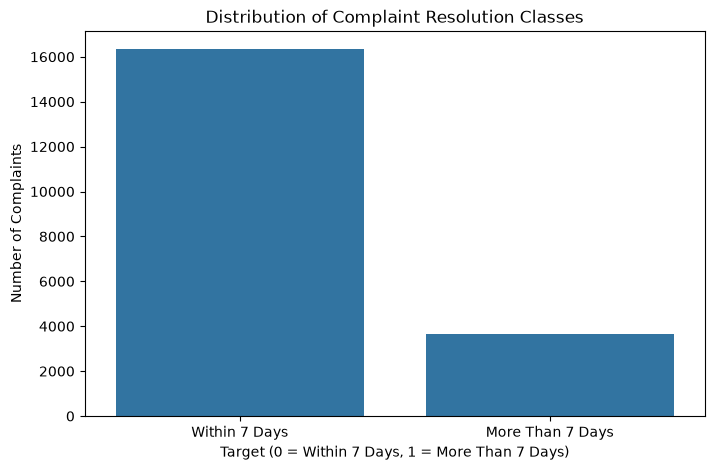

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="target"
)

plt.title("Distribution of Complaint Resolution Classes")
plt.xlabel("Target (0 = Within 7 Days, 1 = More Than 7 Days)")
plt.ylabel("Number of Complaints")
plt.xticks([0, 1], ["Within 7 Days", "More Than 7 Days"])

plt.show()

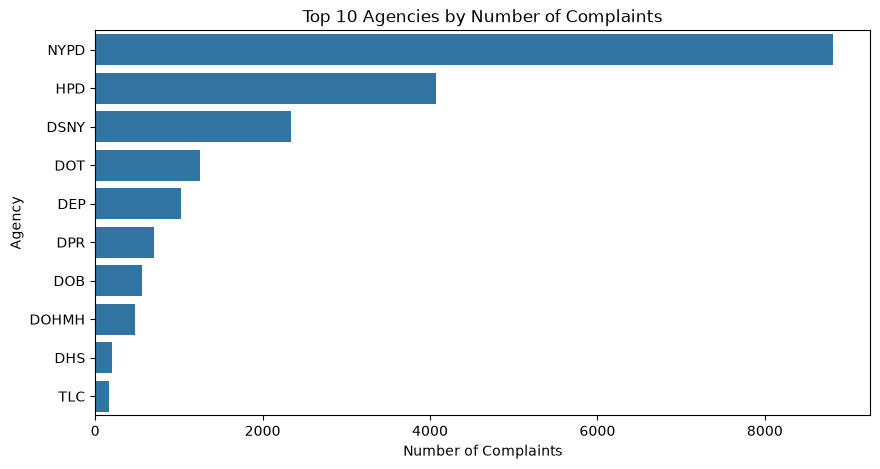

In [11]:
agency_counts = df["agency"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=agency_counts.values,
    y=agency_counts.index
)

plt.title("Top 10 Agencies by Number of Complaints")
plt.xlabel("Number of Complaints")
plt.ylabel("Agency")

plt.show()

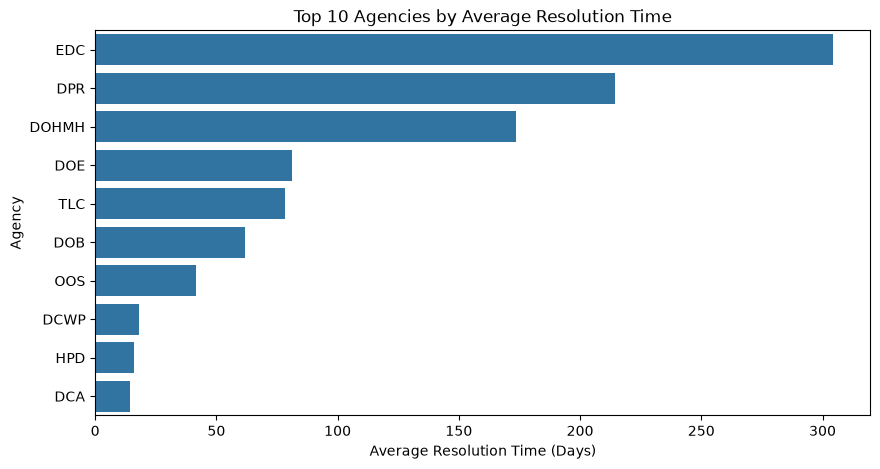

In [12]:
agency_resolution = (
    df.groupby("agency")["resolution_days"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=agency_resolution.values,
    y=agency_resolution.index
)

plt.title("Top 10 Agencies by Average Resolution Time")
plt.xlabel("Average Resolution Time (Days)")
plt.ylabel("Agency")

plt.show()

In [13]:
agency_analysis = df.groupby("agency").agg(
    complaint_count=("unique_key", "count"),
    average_resolution_days=("resolution_days", "mean"),
    median_resolution_days=("resolution_days", "median")
)

agency_analysis = agency_analysis.sort_values(
    "average_resolution_days",
    ascending=False
)

display(agency_analysis.head(10))

,complaint_count,average_resolution_days,median_resolution_days
agency,,,
EDC,145,304.428867,105.933449
DPR,706,214.345117,32.072517
DOHMH,480,173.494364,0.998461
DOE,8,81.147431,25.943281
TLC,161,78.266907,60.950150
DOB,557,61.988596,11.506308
OOS,1,41.655856,41.655856
DCWP,113,18.121399,2.022106
HPD,4076,16.168778,4.133727


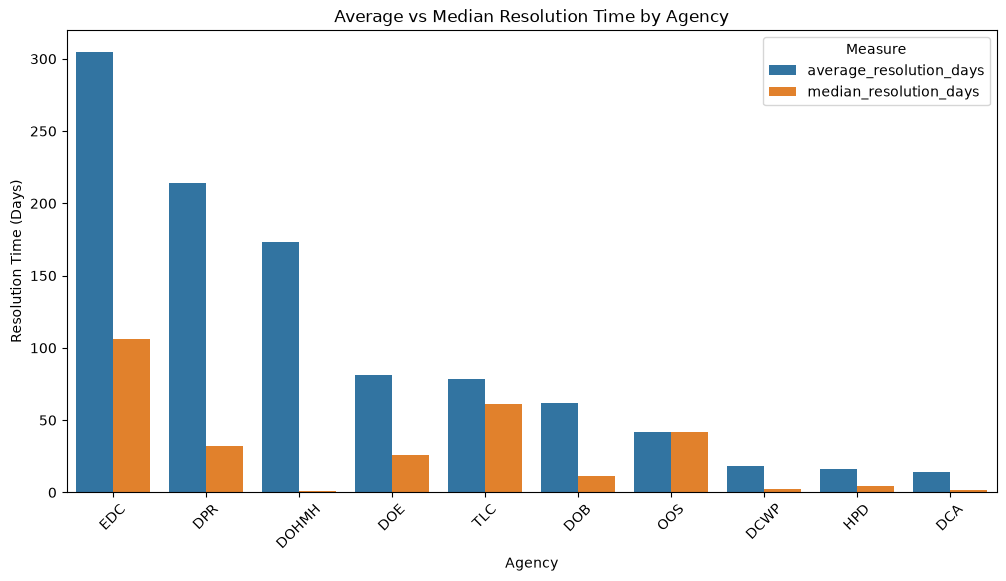

In [14]:
agency_comparison = agency_analysis.head(10).reset_index()

agency_comparison = agency_comparison.melt(
    id_vars="agency",
    value_vars=[
        "average_resolution_days",
        "median_resolution_days"
    ],
    var_name="measure",
    value_name="days"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=agency_comparison,
    x="agency",
    y="days",
    hue="measure"
)

plt.title("Average vs Median Resolution Time by Agency")
plt.xlabel("Agency")
plt.ylabel("Resolution Time (Days)")
plt.xticks(rotation=45)
plt.legend(title="Measure")

plt.show()

In [15]:
# Compare average and median resolution time by agency

agency_comparison = agency_analysis.head(10).copy()

print("Average vs Median Resolution Time by Agency")
print("=" * 65)

print(
    agency_comparison[
        [
            "complaint_count",
            "average_resolution_days",
            "median_resolution_days"
        ]
    ].round(2).to_string()
)

Average vs Median Resolution Time by Agency
        complaint_count  average_resolution_days  median_resolution_days
agency                                                                  
EDC                 145                   304.43                  105.93
DPR                 706                   214.35                   32.07
DOHMH               480                   173.49                    1.00
DOE                   8                    81.15                   25.94
TLC                 161                    78.27                   60.95
DOB                 557                    61.99                   11.51
OOS                   1                    41.66                   41.66
DCWP                113                    18.12                    2.02
HPD                4076                    16.17                    4.13
DCA                  31                    14.20                    1.95


### Interpretation

The analysis shows considerable differences in complaint resolution times across agencies. EDC and DPR have the highest average resolution times. However, some agencies, such as DOHMH, have a large difference between their average and median, suggesting the presence of unusually long cases. HPD has a high complaint count of 4,076. Agencies with very few complaints should be interpreted cautiously.

In [16]:
# Top 10 complaint types by number of complaints

complaint_counts = df["complaint_type"].value_counts().head(10)

print("Top 10 Complaint Types")
print("=" * 50)
print(complaint_counts.to_string())

Top 10 Complaint Types
complaint_type
Illegal Parking                        2475
Noise - Residential                    2424
HEAT/HOT WATER                         1549
Noise - Street/Sidewalk                1008
Blocked Driveway                        907
Request Large Bulky Item Collection     642
UNSANITARY CONDITION                    606
Noise - Vehicle                         419
Street Condition                        419
Water System                            381


### Interpretation

Illegal Parking (2,475) is the most common complaint type, followed by Noise - Residential (2,424) and HEAT/HOT WATER (1,549). Noise-related complaints appear in multiple top categories. This indicates that parking, noise, housing, and sanitation are significant areas of public complaints in our dataset.

In [17]:
complaint_analysis = df.groupby("complaint_type").agg(
    complaint_count=("unique_key", "count"),
    average_resolution_days=("resolution_days", "mean"),
    median_resolution_days=("resolution_days", "median")
)

# Consider complaint types with at least 100 records
complaint_analysis = complaint_analysis[
    complaint_analysis["complaint_count"] >= 100
]

# Sort by average resolution time
complaint_analysis = complaint_analysis.sort_values(
    "average_resolution_days",
    ascending=False
)

print("Top 10 Complaint Types by Average Resolution Time")
print("=" * 75)

print(
    complaint_analysis.head(10).round(2).to_string()
)

Top 10 Complaint Types by Average Resolution Time
                               complaint_count  average_resolution_days  median_resolution_days
complaint_type                                                                                 
Overgrown Tree/Branches                    118                   312.38                   42.41
Noise - Helicopter                         145                   304.43                  105.93
Building/Use                               117                   126.39                   71.39
Damaged Tree                               170                   105.19                   11.53
Maintenance or Facility                    122                    74.94                   11.67
General Construction/Plumbing              199                    55.54                    5.29
APPLIANCE                                  133                    33.07                   15.77
GENERAL                                    179                    31.06               

### Interpretation

Resolution times vary considerably across complaint types. Overgrown Tree/Branches has the highest average resolution time (312.38 days), followed by Noise - Helicopter (304.43 days). Some categories show large differences between average and median resolution times, indicating the influence of unusually long cases. Only complaint types with at least 100 records were included in this analysis.

In [18]:
# Calculate delayed complaint percentage by complaint type

complaint_delay = df.groupby("complaint_type").agg(
    complaint_count=("target", "count"),
    delayed_complaints=("target", "sum")
)

complaint_delay["delayed_percentage"] = (
    complaint_delay["delayed_complaints"]
    / complaint_delay["complaint_count"]
) * 100

# Keep complaint types with at least 100 records
complaint_delay = complaint_delay[
    complaint_delay["complaint_count"] >= 100
]

# Show complaint types with the highest delayed percentage
complaint_delay = complaint_delay.sort_values(
    "delayed_percentage",
    ascending=False
)

print("Top 10 Complaint Types by Delayed Complaint Percentage")
print("=" * 75)

print(
    complaint_delay.head(10).round(2).to_string()
)

Top 10 Complaint Types by Delayed Complaint Percentage
                         complaint_count  delayed_complaints  delayed_percentage
complaint_type                                                                  
Noise - Helicopter                   145                 142               97.93
Building/Use                         117                  96               82.05
APPLIANCE                            133                 100               75.19
GENERAL                              179                 123               68.72
Overgrown Tree/Branches              118                  78               66.10
DOOR/WINDOW                          250                 164               65.60
WATER LEAK                           262                 171               65.27
Maintenance or Facility              122                  75               61.48
FLOORING/STAIRS                      145                  89               61.38
UNSANITARY CONDITION                 606              

### Interpretation

Noise - Helicopter has the highest delayed complaint percentage (97.93%), followed by Building/Use (82.05%) and APPLIANCE (75.19%). These findings suggest that resolution delays vary across complaint types. Therefore, complaint_type may be an important predictive feature for CivicFix.

In [19]:
# Extract month from complaint creation date
df["created_month"] = df["created_date"].dt.month

# Calculate monthly complaint statistics
monthly_analysis = df.groupby("created_month").agg(
    complaint_count=("target", "count"),
    delayed_complaints=("target", "sum")
)

monthly_analysis["delayed_percentage"] = (
    monthly_analysis["delayed_complaints"]
    / monthly_analysis["complaint_count"]
) * 100

print("Monthly Complaint Analysis")
print("=" * 65)

print(monthly_analysis.round(2).to_string())

Monthly Complaint Analysis
               complaint_count  delayed_complaints  delayed_percentage
created_month                                                         
1                         1618                 289               17.86
2                         1360                 237               17.43
3                         1511                 295               19.52
4                         1453                 269               18.51
5                         1676                 271               16.17
6                         1796                 363               20.21
7                         1848                 336               18.18
8                         1788                 351               19.63
9                         1794                 308               17.17
10                        1815                 316               17.41
11                        1655                 353               21.33
12                        1686                 282

### Interpretation

Monthly complaint analysis shows that delayed complaint percentages vary across the year. November has the highest delayed percentage (21.33%), followed by June (20.21%). May has the lowest percentage (16.17%). These differences suggest that the month of complaint creation may provide useful information for predicting resolution delays.

In [20]:
# Extract day of the week
df["created_weekday"] = df["created_date"].dt.day_name()

# Calculate weekday complaint statistics
weekday_analysis = df.groupby("created_weekday").agg(
    complaint_count=("target", "count"),
    delayed_complaints=("target", "sum")
)

weekday_analysis["delayed_percentage"] = (
    weekday_analysis["delayed_complaints"]
    / weekday_analysis["complaint_count"]
) * 100

# Arrange days in calendar order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_analysis = weekday_analysis.reindex(weekday_order)

print("Complaint Analysis by Day of the Week")
print("=" * 65)

print(weekday_analysis.round(2).to_string())

Complaint Analysis by Day of the Week
                 complaint_count  delayed_complaints  delayed_percentage
created_weekday                                                         
Monday                      2474                 450               18.19
Tuesday                     3961                 776               19.59
Wednesday                   3211                 710               22.11
Thursday                    2165                 451               20.83
Friday                      2545                 543               21.34
Saturday                    2439                 354               14.51
Sunday                      3205                 386               12.04


### Interpretation

Wednesday has the highest delayed complaint percentage (22.11%), followed by Friday (21.34%) and Thursday (20.83%). Sunday has the lowest percentage (12.04%). Weekday complaints generally show higher delay percentages than weekend complaints. Therefore, the day of the week may be a useful predictive feature for CivicFix.

In [21]:
# Extract hour from complaint creation date
df["created_hour"] = df["created_date"].dt.hour

# Calculate hourly complaint statistics
hourly_analysis = df.groupby("created_hour").agg(
    complaint_count=("target", "count"),
    delayed_complaints=("target", "sum")
)

hourly_analysis["delayed_percentage"] = (
    hourly_analysis["delayed_complaints"]
    / hourly_analysis["complaint_count"]
) * 100

print("Complaint Analysis by Submission Hour")
print("=" * 70)

print(hourly_analysis.round(2).to_string())

Complaint Analysis by Submission Hour
              complaint_count  delayed_complaints  delayed_percentage
created_hour                                                         
0                         689                  47                6.82
1                         800                  39                4.88
2                         500                  32                6.40
3                         317                  29                9.15
4                         239                  17                7.11
5                         241                  19                7.88
6                         356                  48               13.48
7                         738                 103               13.96
8                         908                 151               16.63
9                        1017                 221               21.73
10                        922                 234               25.38
11                       1193                 312   

### Interpretation

Complaints submitted during daytime hours generally have higher delayed percentages than those submitted late at night. The highest delayed percentage occurs at 1 PM (28.61%), followed by 2 PM (28.50%). The lowest percentage occurs at 1 AM (4.88%). Therefore, submission hour may provide useful information for predicting complaint resolution delays.

In [22]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

print("\nTarget Distribution:")
print(df["target"].value_counts())

print("\nTarget Percentages:")
print(
    (df["target"].value_counts(normalize=True) * 100).round(2)
)

Dataset Shape: (20000, 14)

Missing Values:
unique_key         0
created_date       0
closed_date        0
agency             0
complaint_type     0
descriptor         0
incident_zip       0
borough            0
location_type      0
resolution_days    0
target             0
created_month      0
created_weekday    0
created_hour       0
dtype: int64

Data Types:
unique_key                  int64
created_date       datetime64[us]
closed_date        datetime64[us]
agency                        str
complaint_type                str
descriptor                    str
incident_zip               string
borough                       str
location_type                 str
resolution_days           float64
target                      int64
created_month               int32
created_weekday               str
created_hour                int32
dtype: object

Target Distribution:
target
0    16330
1     3670
Name: count, dtype: int64

Target Percentages:
target
0    81.65
1    18.35
Name: proportion, d

### Final Data Quality Check

The final dataset contains 20,000 records and 14 columns. No missing values were found in any column. The target variable contains two classes: 81.65% of complaints were resolved within 7 days, while 18.35% took more than 7 days. The dataset is ready for final feature preparation.

In [23]:
# Create the final model-ready dataset

model_df = df.drop(
    columns=[
        "unique_key",
        "created_date",
        "closed_date",
        "resolution_days"
    ]
)

print("Model Dataset Shape:", model_df.shape)

print("\nRemaining Columns:")
print(model_df.columns.tolist())

print("\nMissing Values:")
print(model_df.isnull().sum().sum())

display(model_df.head())

Model Dataset Shape: (20000, 10)

Remaining Columns:
['agency', 'complaint_type', 'descriptor', 'incident_zip', 'borough', 'location_type', 'target', 'created_month', 'created_weekday', 'created_hour']

Missing Values:
0


,agency,complaint_type,descriptor,incident_zip,borough,location_type,target,created_month,created_weekday,created_hour
0,DOB,Building/Use,Illegal Conversion Of Residential Building/Space,11378,QUEENS,Unknown,1,1,Tuesday,11
1,DSNY,Request Large Bulky Item Collection,Request Large Bulky Item Collection,11361,QUEENS,Sidewalk,1,1,Monday,17
2,DSNY,Request Large Bulky Item Collection,Request Large Bulky Item Collection,11234,BROOKLYN,Sidewalk,0,1,Tuesday,11
3,NYPD,Noise - Vehicle,Car/Truck Horn,11366,QUEENS,Street/Sidewalk,0,1,Friday,15
4,HPD,SAFETY,SMOKE DETECTOR,11213,BROOKLYN,RESIDENTIAL BUILDING,1,1,Friday,15


In [24]:
# Save the final cleaned dataset

model_df.to_csv(
    "../data/processed/nyc_311_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

print("File: data/processed/nyc_311_cleaned.csv")
print("Shape:", model_df.shape)

Cleaned dataset saved successfully!
File: data/processed/nyc_311_cleaned.csv
Shape: (20000, 10)


In [25]:
check_df = pd.read_csv(
    "../data/processed/nyc_311_cleaned.csv"
)

print("Saved Dataset Shape:", check_df.shape)

print("Missing Values:", check_df.isnull().sum().sum())

print("Duplicate Rows:", check_df.duplicated().sum())

print("\nTarget Distribution:")
print(check_df["target"].value_counts())

display(check_df.head())

Saved Dataset Shape: (20000, 10)
Missing Values: 0
Duplicate Rows: 1247

Target Distribution:
target
0    16330
1     3670
Name: count, dtype: int64


,agency,complaint_type,descriptor,incident_zip,borough,location_type,target,created_month,created_weekday,created_hour
0,DOB,Building/Use,Illegal Conversion Of Residential Building/Space,11378,QUEENS,Unknown,1,1,Tuesday,11
1,DSNY,Request Large Bulky Item Collection,Request Large Bulky Item Collection,11361,QUEENS,Sidewalk,1,1,Monday,17
2,DSNY,Request Large Bulky Item Collection,Request Large Bulky Item Collection,11234,BROOKLYN,Sidewalk,0,1,Tuesday,11
3,NYPD,Noise - Vehicle,Car/Truck Horn,11366,QUEENS,Street/Sidewalk,0,1,Friday,15
4,HPD,SAFETY,SMOKE DETECTOR,11213,BROOKLYN,RESIDENTIAL BUILDING,1,1,Friday,15


In [26]:
print("Original Dataset Shape:", df.shape)

print(
    "Duplicate Complaint IDs:",
    df["unique_key"].duplicated().sum()
)

print(
    "Duplicate Original Rows:",
    df.duplicated().sum()
)

print(
    "Unique Complaint IDs:",
    df["unique_key"].nunique()
)

Original Dataset Shape: (20000, 14)
Duplicate Complaint IDs: 0
Duplicate Original Rows: 0
Unique Complaint IDs: 20000


In [27]:
# Preserve the original complaint date for chronological splitting

model_df["split_date"] = df["created_date"]

# Sort complaints from oldest to newest

model_df = model_df.sort_values(
    by="split_date"
).reset_index(drop=True)

print("Dataset sorted chronologically!")

print("\nFirst 5 records (oldest):")
display(model_df[["split_date", "target"]].head())

print("\nLast 5 records (newest):")
display(model_df[["split_date", "target"]].tail())

Dataset sorted chronologically!

First 5 records (oldest):


,split_date,target
0,2020-01-03 15:41:31,1
1,2020-01-03 15:41:47,1
2,2020-01-03 15:42:00,0
3,2020-01-03 15:42:05,1
4,2020-01-03 15:42:10,1



Last 5 records (newest):


,split_date,target
19995,2025-12-23 09:23:31,0
19996,2025-12-23 09:24:58,0
19997,2025-12-23 09:25:59,0
19998,2025-12-23 09:27:50,0
19999,2025-12-23 09:29:32,0


In [28]:
# Calculate the 80/20 split

split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

print("Training Records:", len(train_df))
print("Testing Records:", len(test_df))

print("\nTraining Period:")
print("Start:", train_df["split_date"].min())
print("End:", train_df["split_date"].max())

print("\nTesting Period:")
print("Start:", test_df["split_date"].min())
print("End:", test_df["split_date"].max())

Training Records: 16000
Testing Records: 4000

Training Period:
Start: 2020-01-03 15:41:31
End: 2024-12-03 12:33:42

Testing Period:
Start: 2024-12-03 12:33:57
End: 2025-12-23 09:29:32


### Chronological Train-Test Split

The dataset was sorted by complaint creation date and divided chronologically into 80% training data (16,000 records) and 20% testing data (4,000 records). The training data contains older complaints, while the testing data contains newer complaints. This approach simulates predicting future complaint resolution times using historical data.

In [ ]:
model_df.to_csv(
    "../data/processed/nyc_311_cleaned.csv",
    index=False
)
 
print("Updated cleaned dataset saved!")
print("Shape:", model_df.shape)

Updated cleaned dataset saved!
Shape: (20000, 11)
